# 作业10

对R语言自带的AirPassengers数据集进行时间序列分析，生成四种趋势图（需安装tseries和forecast包），并生成关于季节性趋势的图表。

## 数据准备

加载包

In [1]:
library(tseries)
library(forecast)

Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 



加载数据

In [2]:
data(AirPassengers)

## 数据分析

### 四种趋势图

#### 时间序列图

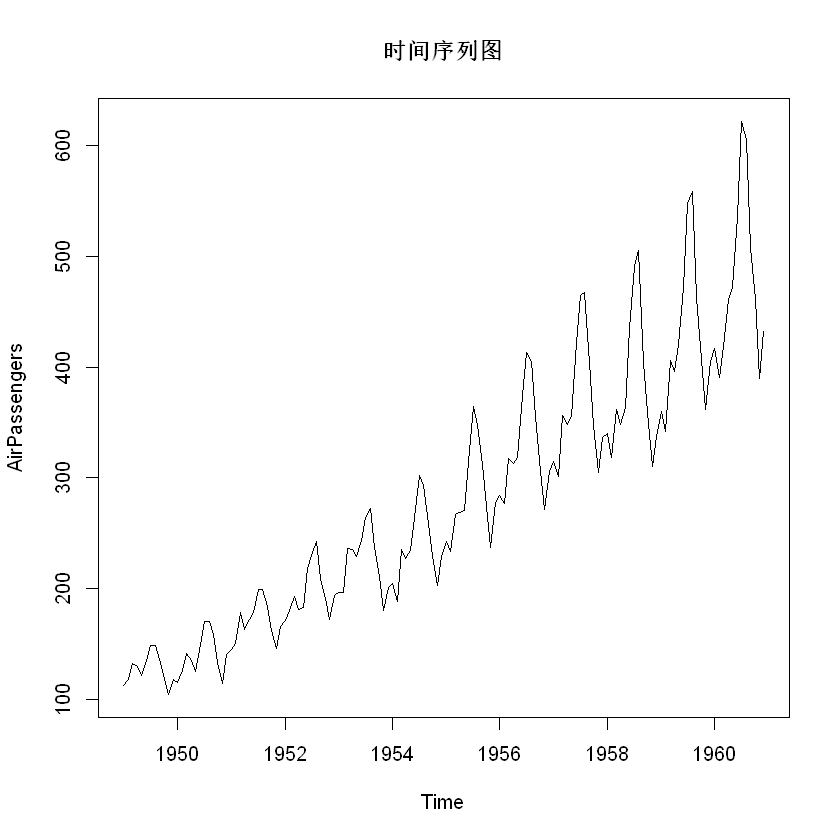

In [3]:
plot(AirPassengers, main = "时间序列图")

从时间序列图中可以看到，航空公司的乘客数量总体呈现线性递增趋势，且存在一定的季节周期性

#### 移动平均趋势图

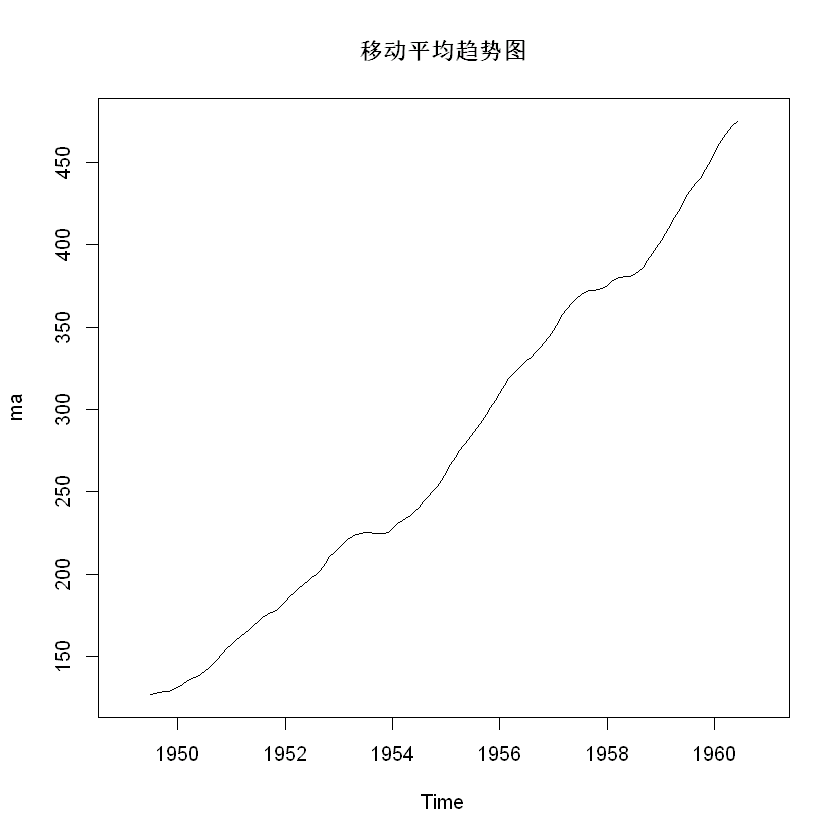

In [4]:
ma <- ma(AirPassengers, order = 12)
plot(ma, main = "移动平均趋势图")

移动平均趋势图呈现平滑的斜向上曲线，体现出航空公司的乘客数量总体呈现上升趋势

#### 自回归趋势图

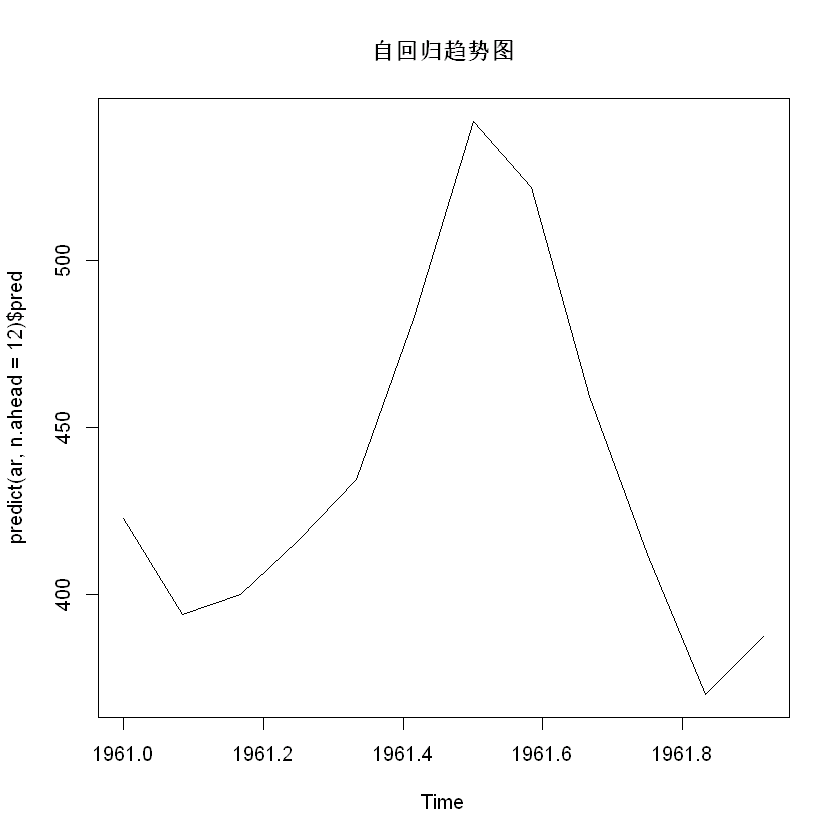

In [5]:
ar <- ar(AirPassengers)
plot(predict(ar, n.ahead = 12)$pred, main = "自回归趋势图")

自回归趋势图在1月、5月、9月出现极值，说明航空公司的乘客数量存在季节性变化

#### 指数平滑趋势图

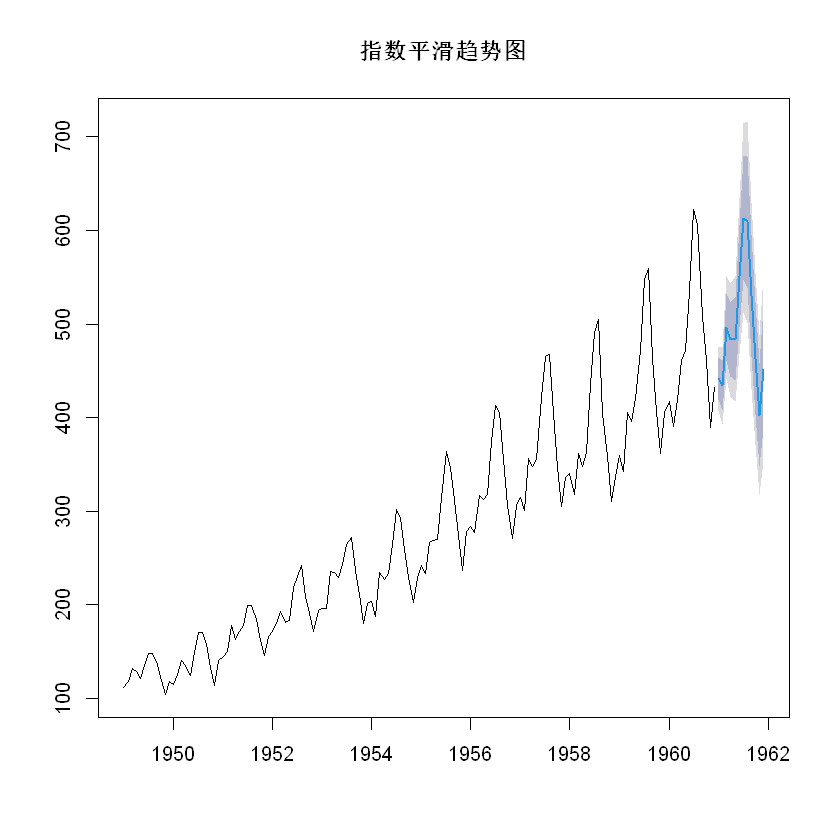

In [6]:
es <- ets(AirPassengers)
plot(forecast(es, h = 12), main = "指数平滑趋势图")

指数平滑趋势图总体为向上倾斜，体现航空公司的乘客数量呈现上升趋势；指数平滑呈现很明显的周期性波动，体现航空公司的乘客数量具有较为明显的季节性变化特点

### 季节性趋势图

#### 季节性图

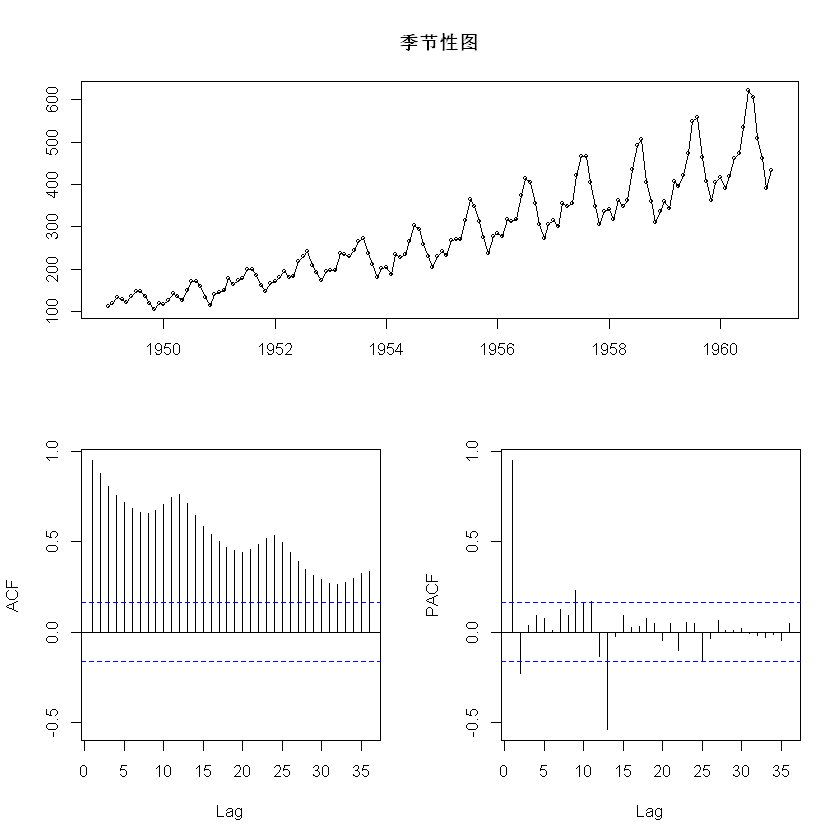

In [7]:
tsdisplay(AirPassengers, main = "季节性图")

#### 季节性子序列图

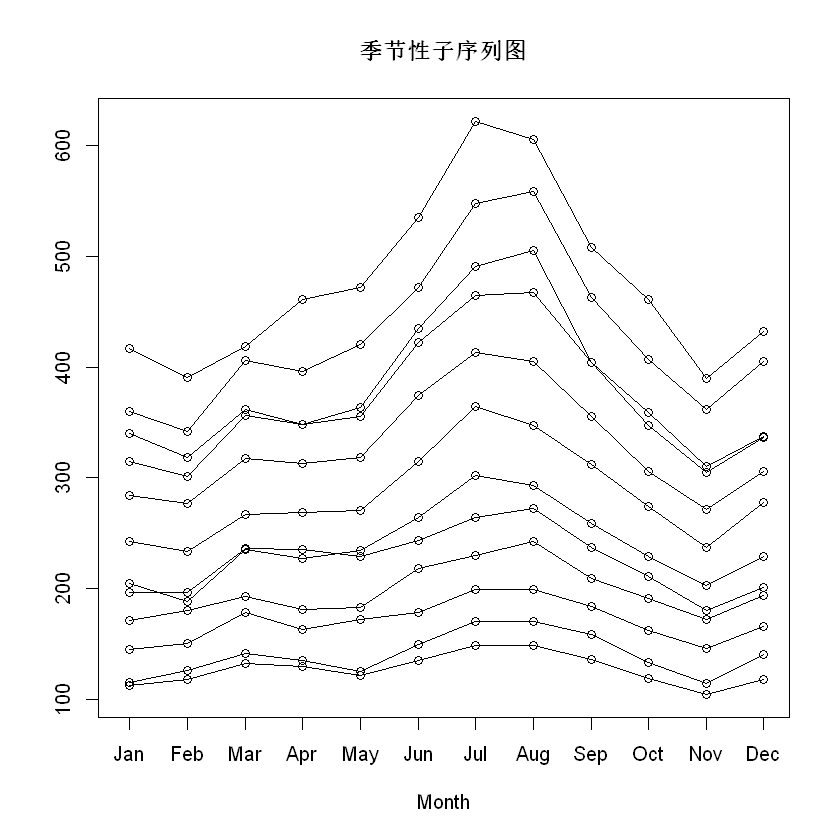

In [8]:
seasonplot(AirPassengers, main = "季节性子序列图")

从季节性子序列图中可以看到，航空公司的乘客数据在不同年份的差别主要是总体数量上的差别，从年内周期变化层面来看，每年数据的季节性变化规律具有相似的特点

#### 自相关函数图

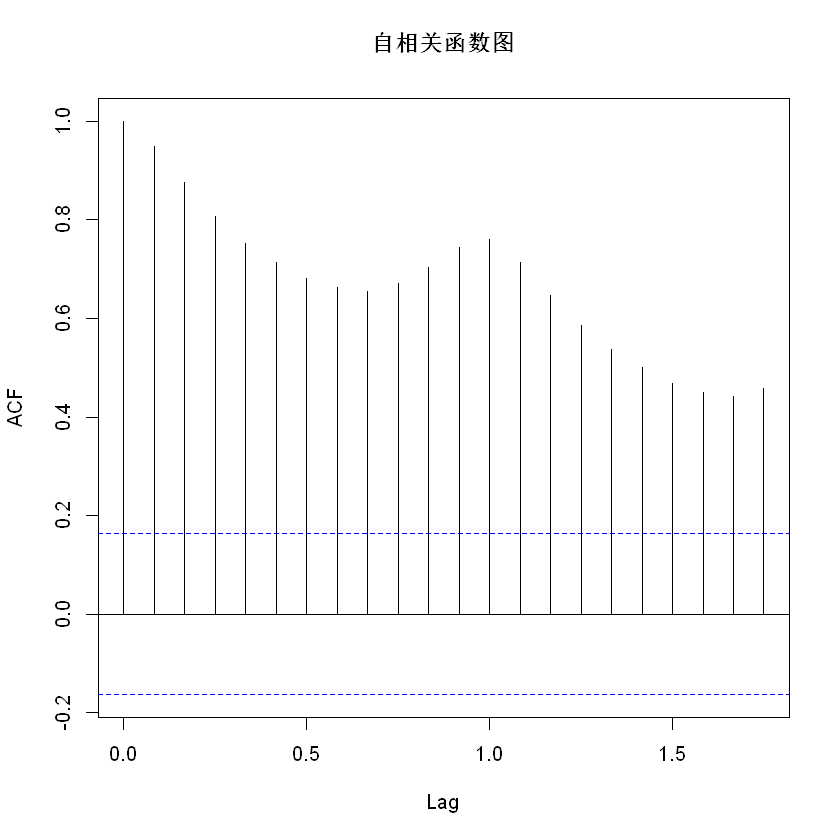

In [9]:
acf(AirPassengers, main = "自相关函数图")

#### 偏自相关函数图

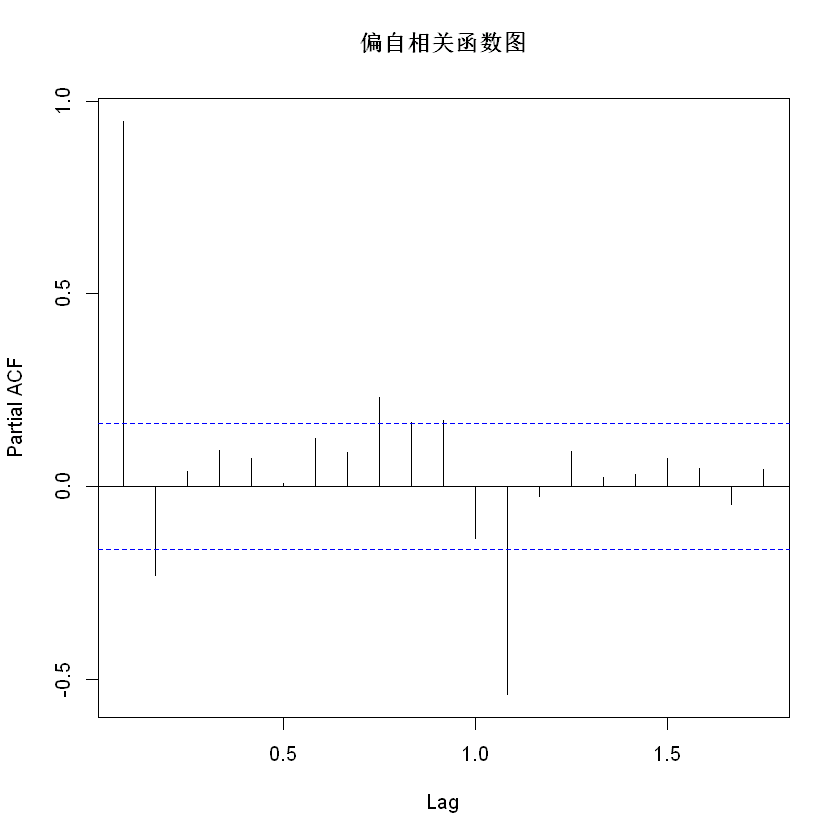

In [10]:
pacf(AirPassengers, main = "偏自相关函数图")

### 四种趋势图的集合：ARIMA模型

根据前面的季节性ACF和PACF图可以看出，AirPassengers数据集存在季节性，并且在自相关和偏自相关函数中都存在明显的周期性。因此，我们需要使用季节性ARIMA（SARIMA）模型来进行分析。

In [11]:
fit <- auto.arima(AirPassengers, seasonal = TRUE)
summary(fit)

Series: AirPassengers 
ARIMA(2,1,1)(0,1,0)[12] 

Coefficients:
         ar1     ar2      ma1
      0.5960  0.2143  -0.9819
s.e.  0.0888  0.0880   0.0292

sigma^2 = 132.3:  log likelihood = -504.92
AIC=1017.85   AICc=1018.17   BIC=1029.35

Training set error measures:
                 ME     RMSE     MAE      MPE     MAPE     MASE        ACF1
Training set 1.3423 10.84619 7.86754 0.420698 2.800458 0.245628 -0.00124847

可以看到，最适合AirPassengers的模型是SARIMA(0,1,1)(0,1,1)[12]模型。可以使用这个模型对AirPassengers进行预测

In [12]:
forecast(fit, h = 12)

         Point Forecast    Lo 80    Hi 80    Lo 95    Hi 95
Jan 1961       445.6349 430.8903 460.3795 423.0851 468.1847
Feb 1961       420.3950 403.0907 437.6993 393.9304 446.8596
Mar 1961       449.1983 429.7726 468.6240 419.4892 478.9074
Apr 1961       491.8399 471.0270 512.6529 460.0092 523.6707
May 1961       503.3945 481.5559 525.2330 469.9953 536.7937
Jun 1961       566.8624 544.2637 589.4612 532.3007 601.4242
Jul 1961       654.2602 631.0820 677.4383 618.8122 689.7081
Aug 1961       638.5975 614.9704 662.2246 602.4630 674.7320
Sep 1961       540.8837 516.9028 564.8647 504.2081 577.5594
Oct 1961       494.1266 469.8624 518.3909 457.0177 531.2356
Nov 1961       423.3327 398.8381 447.8273 385.8715 460.7939
Dec 1961       465.5076 440.8229 490.1923 427.7556 503.2596